# AP 155 Lab Exercise
---
## Exercise 9: Interpolation

_Instructions_:
- **Report figures:** Compare the original data with interpolated reconstructions. Include the synthetic sine example and the sampled real-world dataset, if available. For the real-world dataset, compare sampling levels of 50%, 30%, 10%, and 5%.
- **Report discussion:** Explain how the choice of interpolator and sampling level affects the reconstruction. Discuss limitations, including behavior outside the sampled domain.
- **Code:** Complete the code and ensure it is functional, readable, and efficient. Include concise Markdown documentation highlighting the critical steps.

### Student Information
- _Full Name (Last Name, First Name)_: Lunas, Bryce Enrico
- _Student No._: 2024-01596
- _Section_: THU-TX-1

### Grading Information (c/o Lab Instructor)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figures | XX | 20 |
| Report discussion | XX | 20 |
| Code readability | XX | 20 |
| Code efficiency | XX | 20 |
| Code appropriateness | XX | 20 |
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_

---
## Section 1: Report

### Report figures

**Figure 1. Synthetic data interpolation.** Insert a figure comparing the sampled sine data with the linear, nearest, quadratic, and cubic interpolations.

**Figure 2. Real-world data reconstruction.** Insert the four reconstruction plots for sampling levels of 50%, 30%, 10%, and 5%.

### Report discussion

**Interpolator comparison:** Discuss how the interpolation methods differ and which reproduces the underlying function most accurately for the synthetic data.

- **Nearest** produces a staircase: it is discontinuous and has the largest error, roughly the sample spacing times the local slope of the sine. **Linear** is continuous but has visible corners at the nodes, and it cuts off the peaks and troughs because straight segments cannot follow curvature. **Quadratic and cubic** follow the curvature of the sine wave and track the true function closely between samples.
- **Cubic is the most accurate** for the synthetic data because the underlying function is smooth and a cubic polynomial matches its local shape well. Accuracy depends on the sampling. Where random samples leave a large gap, even cubic deviates noticeably, and all methods are only valid inside the sampled range.

**Sampling-level comparison:** Discuss how reconstruction quality changes as the number of sampled data points decreases. Mention limitations and any visible artifacts.

- Reconstruction quality degrades steadily as the retained fraction falls from 50% to 5%, with the linear-interpolation RMSE rising from 103.83 at 50% to 336.68 at 5%: the curve is nearly indistinguishable from the original at 50% and 30%, loses short-term fluctuations at 10%, and keeps only the broad trend at 5%. Because the samples are random, long gaps occur by chance and the largest errors concentrate there, while linear segments smooth over sharp turns. The reconstruction also only covers the span between the first and last retained points, so it can start late or end early (most visible at 5%), and interpolation can never recover the fluctuations that were discarded.

### Other comments
Sir, do we have practical exams on AP155 or just the written exams that Ma'am Lim facilitates?

Method              RMSE   max |err|
nearest         2.25e-01    8.53e-01
linear          8.11e-02    2.29e-01
quadratic       1.71e-02    6.63e-02
cubic           9.14e-03    3.11e-02


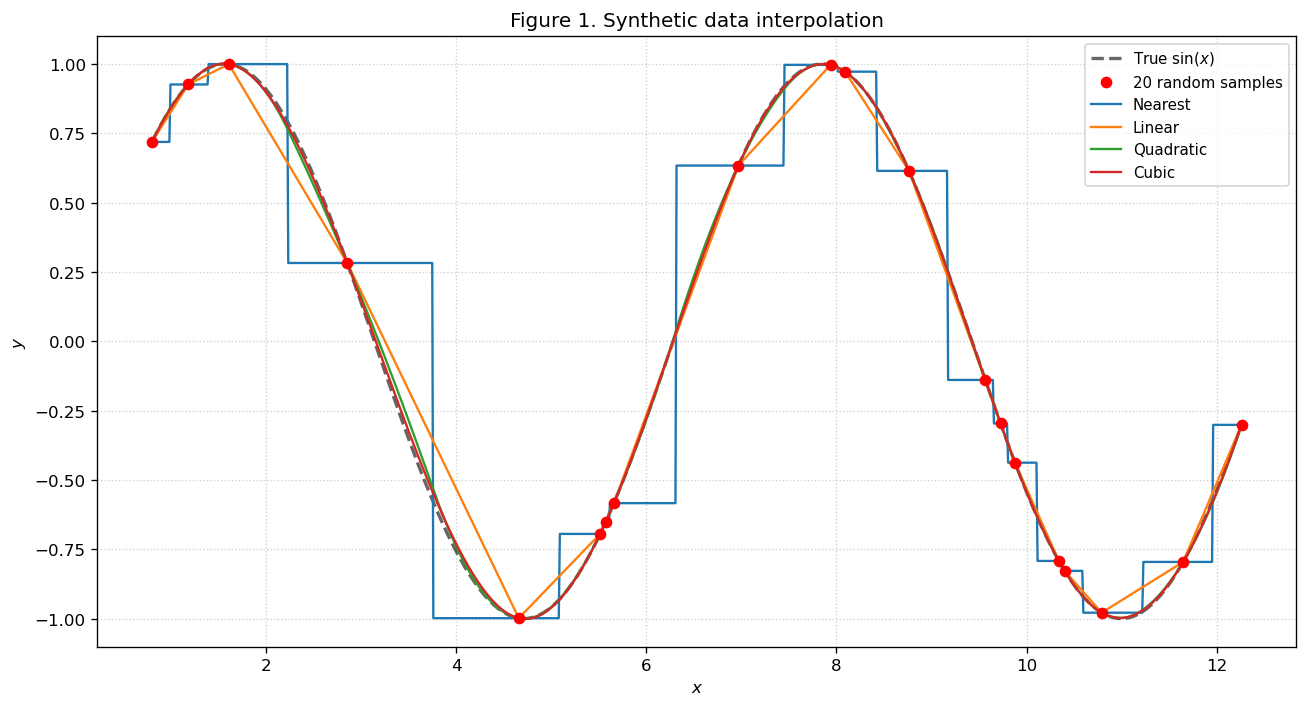

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

rng = np.random.default_rng(42)
xs = np.sort(rng.uniform(0, 4 * np.pi, 20))
ys = np.sin(xs)

xe = np.linspace(xs[0], xs[-1], 1000)          # inside the sampled range only
kinds = ["nearest", "linear", "quadratic", "cubic"]
recon = {k: interp1d(xs, ys, kind=k)(xe) for k in kinds}

print(f"{'Method':<12}{'RMSE':>12}{'max |err|':>12}")
for k, yi in recon.items():
    err = yi - np.sin(xe)
    print(f"{k:<12}{np.sqrt(np.mean(err**2)):>12.2e}{np.abs(err).max():>12.2e}")

# Figure 1
fig, ax = plt.subplots(figsize=(11, 6), dpi=120)
ax.plot(xe, np.sin(xe), "k--", lw=2, alpha=0.6, label=r"True $\sin(x)$")
ax.plot(xs, ys, "ro", ms=6, zorder=5, label=f"{xs.size} random samples")
for k, yi in recon.items():
    ax.plot(xe, yi, lw=1.4, label=k.capitalize())
ax.set(xlabel=r"$x$", ylabel=r"$y$", title="Figure 1. Synthetic data interpolation")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, ls=":", alpha=0.6)
fig.tight_layout()
plt.show()

![Figure 2. Dow Jones reconstruction at 50%, 30%, 10%, and 5%](figure2.png)

--2026-10-20 07:44:01--  https://websites.umich.edu/~mejn/cp/data/dow.txt
Resolving websites.umich.edu (websites.umich.edu)... 162.159.140.37, 172.66.0.37, 2606:4700:7::25, ...
Connecting to websites.umich.edu (websites.umich.edu)|162.159.140.37|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 8845 (8.6K) [text/plain]
Saving to: ‘dow.txt’

dow.txt             100%[===================>]   8.64K  --.-KB/s    in 0s      

2026-10-20 07:44:02 (36.7 MB/s) - ‘dow.txt’ saved [8845/8845]

Fraction        RMSE   max |err|
50%           123.21      916.20
30%           173.63     1224.95
10%           332.36     2008.63
5%            593.42     2817.48


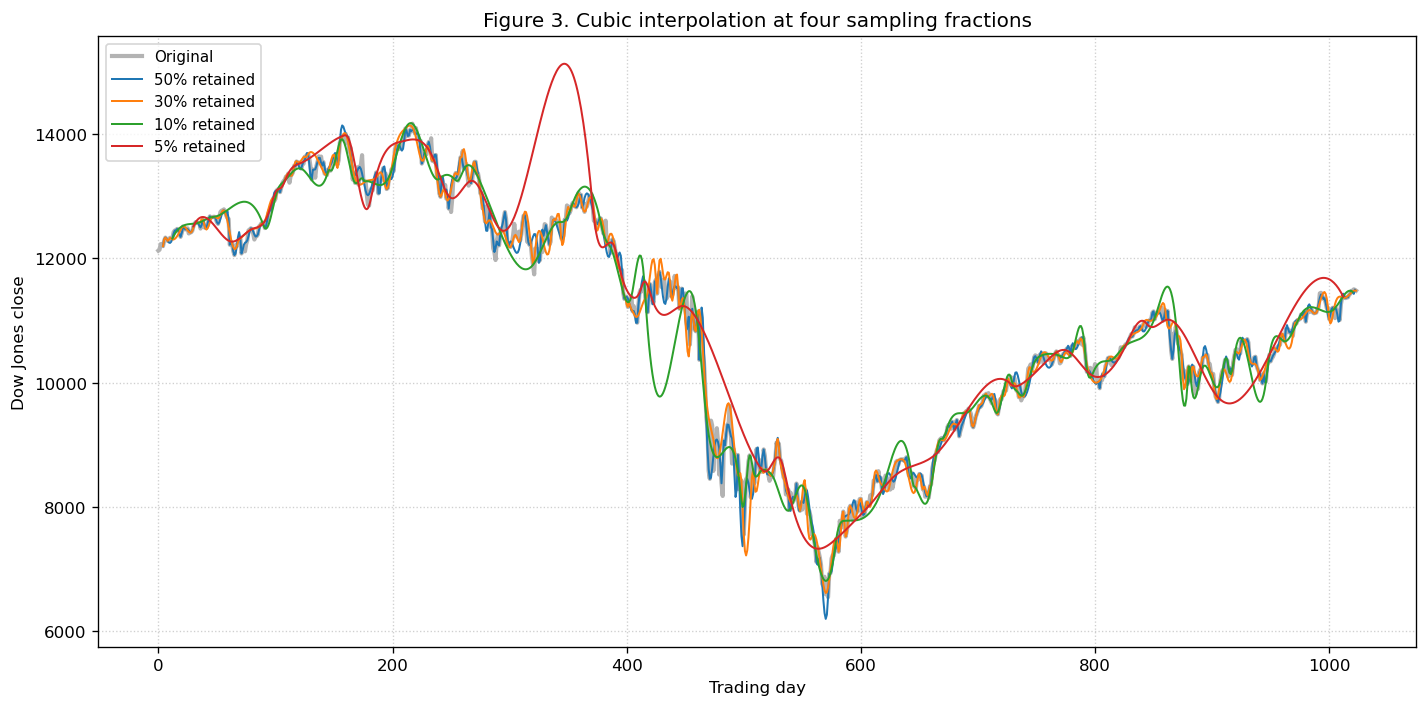

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import interp1d

!wget -nc https://websites.umich.edu/~mejn/cp/data/dow.txt

y_full = np.loadtxt('dow.txt')
x_full = np.arange(len(y_full))

METHOD = 'cubic'                     
fractions = [0.50, 0.30, 0.10, 0.05]

rng = np.random.default_rng(42)
fig, ax = plt.subplots(figsize=(12, 6), dpi=120)
ax.plot(x_full, y_full, color='0.7', lw=2.5, label='Original')

print(f"{'Fraction':<10}{'RMSE':>10}{'max |err|':>12}")
for frac in fractions:
    idx = np.sort(rng.choice(len(x_full), size=round(frac * len(x_full)), replace=False))
    xs, ys = x_full[idx], y_full[idx]

    xe = x_full[(x_full >= xs[0]) & (x_full <= xs[-1])]    # no extrapolation
    ye = interp1d(xs, ys, kind=METHOD)(xe)

    err = ye - y_full[xe]
    print(f"{frac:<10.0%}{np.sqrt(np.mean(err**2)):>10.2f}{np.abs(err).max():>12.2f}")
    ax.plot(xe, ye, lw=1.2, label=f'{frac:.0%} retained')

ax.set(xlabel='Trading day', ylabel='Dow Jones close',
       title=f'Figure 3. {METHOD.capitalize()} interpolation at four sampling fractions')
ax.legend(loc='upper left', fontsize=9)
ax.grid(True, ls=':', alpha=0.6)
fig.tight_layout()
plt.savefig("figure3.png", dpi=200, bbox_inches="tight")
plt.show()

---
## Section 2: Code

In [2]:
# import numpy as np
# import matplotlib.pyplot as plt
# from scipy import interpolate
# from pathlib import Path

# rng = np.random.default_rng(42)

### Problem 1: Interpolation of synthetic data

Generate random samples from a known sine function, then compare several interpolation methods. The interpolators only reconstruct values within the sampled domain; they should not be treated as reliable extrapolators outside it.

Method                     max |error|          RMSE
Nearest neighbor             7.644e-01     1.829e-01
Piecewise linear             1.565e-01     5.039e-02
Lagrange (barycentric)       1.541e-06     1.450e-07
Natural cubic spline         1.135e-02     2.867e-03


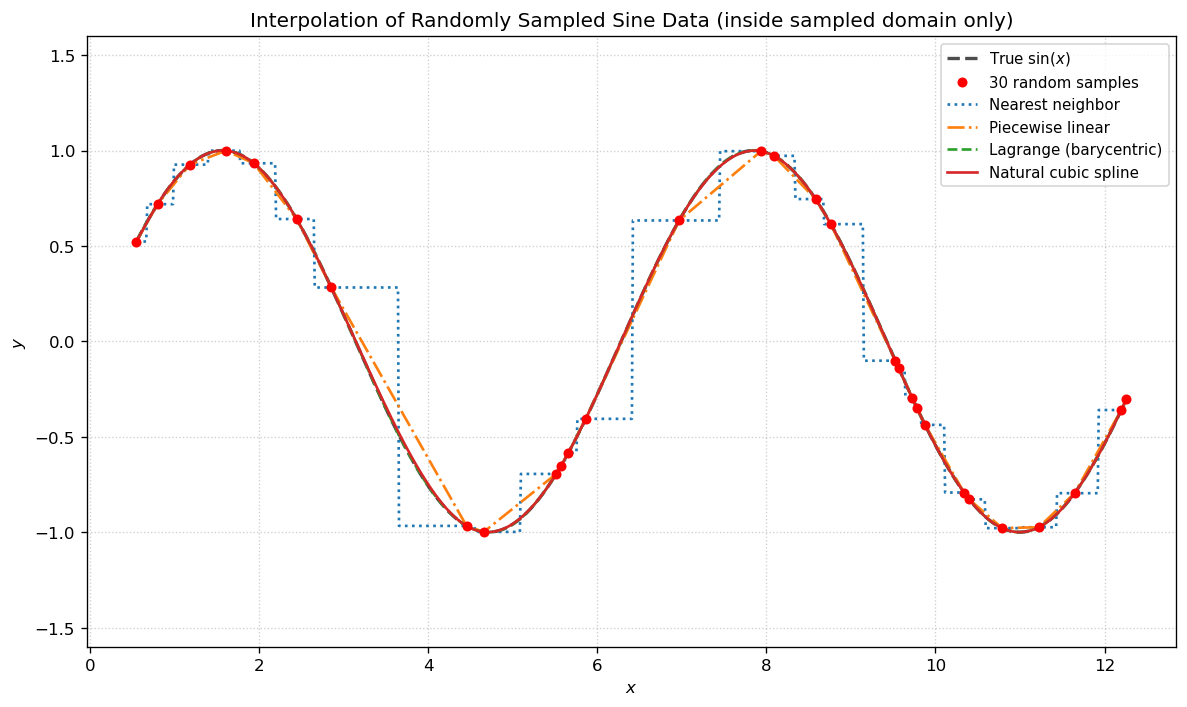

In [8]:
# code here

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator 
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline, BarycentricInterpolator  

# Set-up
X_MIN, X_MAX = 0.0, 4 * np.pi   # two full periods
N_SAMPLES = 30

def f(x):
    return np.sin(x)

rng = np.random.default_rng(42)
xs = np.sort(rng.uniform(X_MIN, X_MAX, N_SAMPLES))  
ys = f(xs)

# Evaluate only inside the sampled domain [xs[0], xs[-1]]
x_eval = np.linspace(xs[0], xs[-1], 1000)
y_true = f(x_eval)

def check_domain(xs, x):
    if np.any(x < xs[0]) or np.any(x > xs[-1]):
        raise ValueError("Interpolation only: x lies outside the sampled domain.")

# Interpolators
def nearest(xs, ys, x):
    check_domain(xs, x)
    i = np.clip(np.searchsorted(xs, x), 1, len(xs) - 1)
    pick = np.where(x - xs[i-1] < xs[i] - x, i - 1, i)
    return ys[pick]

def linear(xs, ys, x):
    check_domain(xs, x)
    i = np.clip(np.searchsorted(xs, x) - 1, 0, len(xs) - 2)
    t = (x - xs[i]) / (xs[i+1] - xs[i])
    return ys[i] + t * (ys[i+1] - ys[i])

def lagrange_barycentric(xs, ys, x):
    """Degree n-1 interpolating polynomial, second barycentric form."""
    check_domain(xs, x)
    w = np.array([1.0 / np.prod(xs[j] - np.delete(xs, j)) for j in range(len(xs))])
    d = x[:, None] - xs[None, :]
    hit = (d == 0)
    d[hit] = 1.0
    t = w / d
    p = (t @ ys) / t.sum(axis=1)
    rows = hit.any(axis=1)
    p[rows] = ys[hit[rows].argmax(axis=1)]
    return p

def natural_cubic_spline(xs, ys, x):
    """Natural spline (S'' = 0 at both ends); solve for second derivatives."""
    check_domain(xs, x)
    N = len(xs)
    h = np.diff(xs)
    A = np.zeros((N, N))
    b = np.zeros(N)
    A[0, 0] = A[-1, -1] = 1.0
    for i in range(1, N - 1):
        A[i, i-1], A[i, i], A[i, i+1] = h[i-1], 2*(h[i-1] + h[i]), h[i]
        b[i] = 6*((ys[i+1] - ys[i])/h[i] - (ys[i] - ys[i-1])/h[i-1])
    M = np.linalg.solve(A, b)

    i = np.clip(np.searchsorted(xs, x) - 1, 0, N - 2)
    hi = h[i]
    a, c = xs[i+1] - x, x - xs[i]
    return (M[i]*a**3 + M[i+1]*c**3) / (6*hi) \
         + (ys[i]/hi   - M[i]*hi/6)   * a \
         + (ys[i+1]/hi - M[i+1]*hi/6) * c

methods = {
    "Nearest neighbor":       (nearest,              ":"),
    "Piecewise linear":       (linear,               "-."),
    "Lagrange (barycentric)": (lagrange_barycentric, "--"),
    "Natural cubic spline":   (natural_cubic_spline, "-"),
}
results = {k: fn(xs, ys, x_eval) for k, (fn, _) in methods.items()}

print(f"{'Method':<24}{'max |error|':>14}{'RMSE':>14}")
for k, y in results.items():
    err = y - y_true
    print(f"{k:<24}{np.abs(err).max():>14.3e}{np.sqrt(np.mean(err**2)):>14.3e}")

# Plot
fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

ax.plot(x_eval, y_true, "k--", lw=2, alpha=0.7, label=r"True $\sin(x)$")
ax.plot(xs, ys, "ro", ms=5, zorder=5, label=f"{N_SAMPLES} random samples")
for k, y in results.items():
    ax.plot(x_eval, y, methods[k][1], lw=1.6, label=k)

ax.set(xlabel=r"$x$", ylabel=r"$y$", ylim=(-1.6, 1.6),
       title="Interpolation of Randomly Sampled Sine Data (inside sampled domain only)")
ax.legend(loc="upper right", fontsize=9)
ax.grid(True, ls=":", alpha=0.6)
fig.tight_layout()
plt.show()

**Problem 1: Code Summary**

This script samples a known function, sin(x), at random points and compares nearest-neighbor, linear, barycentric Lagrange, and natural cubic spline interpolation against the true curve. I implemented the methods from scratch (checking two against SciPy) because the point is to understand how each one builds its interpolant, and I used the barycentric form of the polynomial because it is stable and handles evaluation points that land exactly on a node. Evaluation is restricted to [x_min, x_max] of the samples and raises an error outside it, since interpolants are unreliable when extrapolated.

### Problem 2: Interpolation of real-world data

Load the Dow Jones time-series dataset, randomly retain a specified fraction of observations, and compare the reconstructed curve with the original series. The sampling fractions are 50%, 30%, 10%, and 5%. 

In [5]:
# !wget --quiet https://www-personal.umich.edu/~mejn/cp/data/dow.txt

In [4]:
# load the dataset; download it first if needed
# path is https://websites.umich.edu/~mejn/cp/data/dow.txt

File ‘dow.txt’ already there; not retrieving.

50% retained: RMSE = 103.83
30% retained: RMSE = 132.84
10% retained: RMSE = 219.32
5% retained: RMSE = 336.68


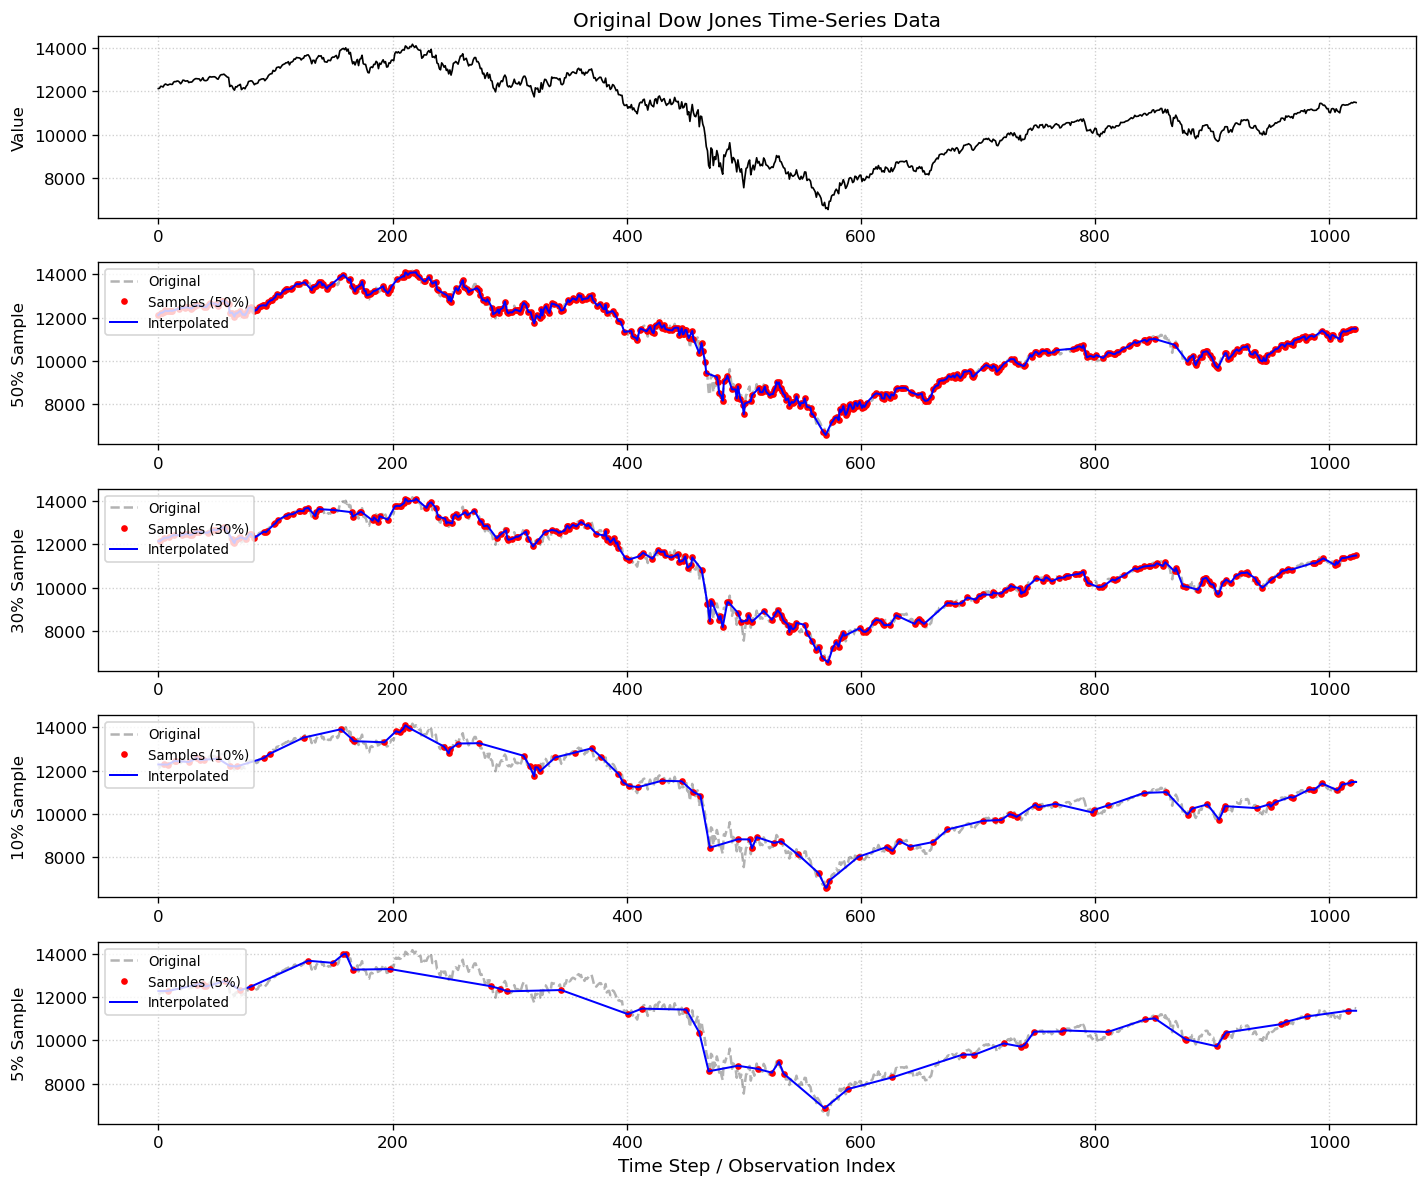

In [10]:
import numpy as np
import matplotlib.pyplot as plt

!wget -nc https://websites.umich.edu/~mejn/cp/data/dow.txt

y_full = np.loadtxt('dow.txt')
x_full = np.arange(len(y_full))

fractions = [0.50, 0.30, 0.10, 0.05]

plt.figure(figsize=(12, 10), dpi=120)

plt.subplot(len(fractions) + 1, 1, 1)
plt.plot(x_full, y_full, 'k-', linewidth=1, label='Original Series')
plt.title('Original Dow Jones Time-Series Data', fontsize=12)
plt.ylabel('Value')
plt.grid(True, linestyle=':', alpha=0.6)

np.random.seed(42)  # For reproducible random sampling
for i, frac in enumerate(fractions, start=2):
    num_samples = int(frac * len(x_full))
    sampled_indices = np.sort(np.random.choice(len(x_full), size=num_samples, replace=False))
    
    x_sample = x_full[sampled_indices]
    y_sample = y_full[sampled_indices]
    
    y_interp = np.interp(x_full, x_sample, y_sample)
    mask = (x_full >= x_sample[0]) & (x_full <= x_sample[-1])
    rmse = np.sqrt(np.mean((y_interp[mask] - y_full[mask])**2))
    print(f"{frac:.0%} retained: RMSE = {rmse:.2f}")
    
    plt.subplot(len(fractions) + 1, 1, i)
    plt.plot(x_full, y_full, 'k--', alpha=0.3, label='Original')
    plt.plot(x_sample, y_sample, 'ro', markersize=3, label=f'Samples ({int(frac*100)}%)')
    plt.plot(x_full, y_interp, 'b-', linewidth=1.2, label='Interpolated')
    
    plt.ylabel(f'{int(frac*100)}% Sample')
    plt.legend(loc='upper left', fontsize=8, frameon=True)
    plt.grid(True, linestyle=':', alpha=0.6)

plt.xlabel('Time Step / Observation Index', fontsize=11)
plt.tight_layout()
plt.savefig("figure2.png", dpi=200, bbox_inches="tight")
plt.show()

**Problem 2: Code Summary**

This script keeps a random fraction (50%, 30%, 10%, 5%) of the Dow Jones series and reconstructs the full curve with linear and natural cubic spline interpolation, so the loss of accuracy as data thins out can be seen in the plots and measured with RMSE and max error. Moreover, samples are drawn without replacement and sorted so the interpolators receive increasing x values, and the same random generator is reused so the results are reproducible. Reconstruction is evaluated only between the first and last retained points, because extrapolating beyond them would be guesswork rather than interpolation.

### Problem 3: Compare interpolation methods on the sampled real-world data

Use a single sampling fraction to compare linear, quadratic, and cubic interpolation. Higher-order interpolation can produce smoother curves, but it can also overshoot between sparse or rapidly changing observations.

Method            RMSE   max |err|
linear          308.15     1234.90
quadratic       335.72     1481.21
cubic           341.01     1464.26


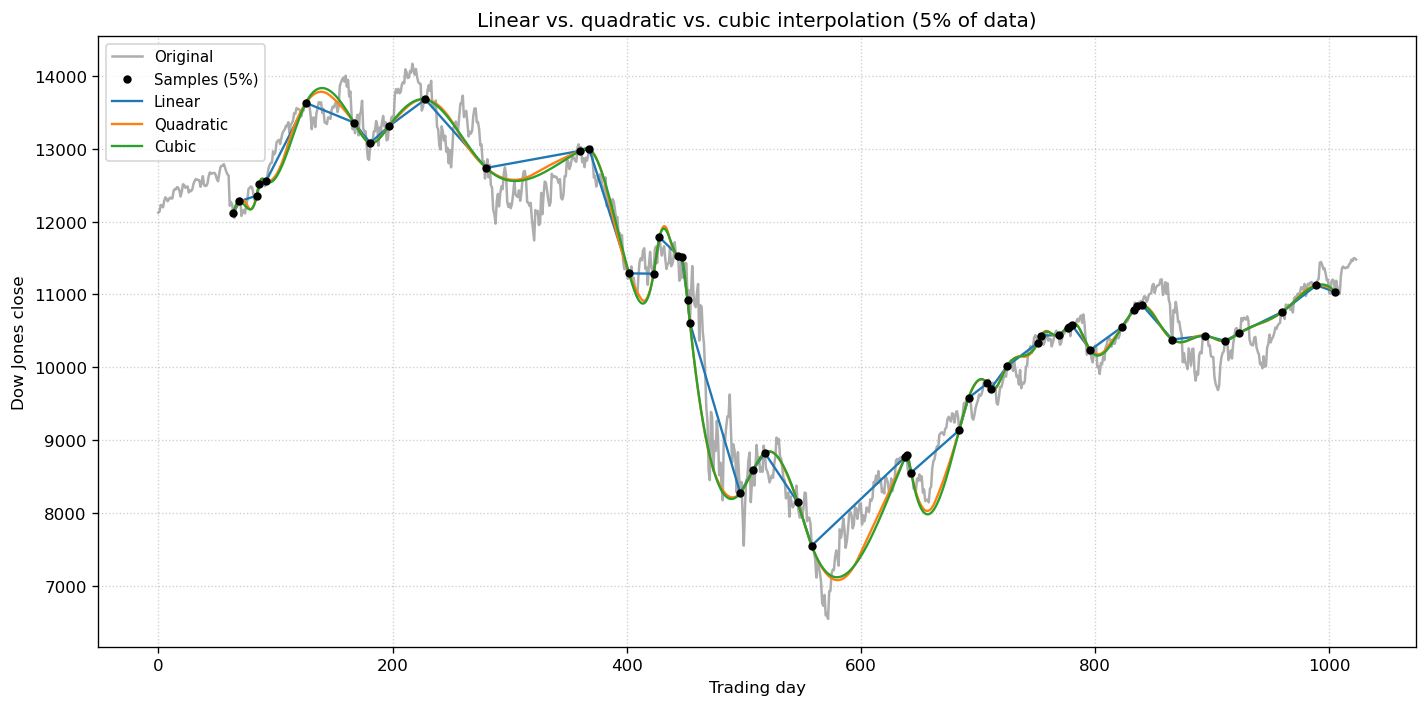

In [4]:
# code here

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from urllib.request import urlretrieve
from scipy.interpolate import interp1d

URL, FILE = "https://websites.umich.edu/~mejn/cp/data/dow.txt", "dow.txt"
if not Path(FILE).exists():
    urlretrieve(URL, FILE)

y = np.loadtxt(FILE)
t = np.arange(y.size)                     

FRACTION = 0.05
rng = np.random.default_rng(42)
keep = np.sort(rng.choice(t.size, size=round(FRACTION * t.size), replace=False))
ts, ys = t[keep], y[keep]

# We evaluate only inside the sample range
te = t[(t >= ts[0]) & (t <= ts[-1])]
kinds = ["linear", "quadratic", "cubic"]
recon = {k: interp1d(ts, ys, kind=k)(te) for k in kinds}

# Errors
print(f"{'Method':<12}{'RMSE':>10}{'max |err|':>12}")
for k, yi in recon.items():
    err = yi - y[te]
    print(f"{k:<12}{np.sqrt(np.mean(err**2)):>10.2f}{np.abs(err).max():>12.2f}")

# Plot
fig, ax = plt.subplots(figsize=(12, 6), dpi=120)

ax.plot(t, y, color="0.6", lw=1.5, alpha=0.8, label="Original")
ax.plot(ts, ys, "ko", ms=4, zorder=5, label=f"Samples ({FRACTION:.0%})")
for k, yi in recon.items():
    ax.plot(te, yi, lw=1.4, label=k.capitalize())

ax.set(xlabel="Trading day", ylabel="Dow Jones close",
       title=f"Linear vs. quadratic vs. cubic interpolation ({FRACTION:.0%} of data)")
ax.legend(loc="upper left", fontsize=9)
ax.grid(True, ls=":", alpha=0.6)
fig.tight_layout()
plt.show()

**Problem 3: Code Summary**

I've written the code this way so that it keeps only 5% of the Dow Jones data and compares linear, quadratic, and cubic interpolation to show how higher-order methods can overshoot the data between widely spaced samples, while linear interpolation cannot leave the range of its neighboring points. Furthermore, I used SciPy's interp1d with its default bounds checking, evaluated only inside the sampled range, so that no extrapolation is silently included in the comparison. RMSE and max error are printed alongside the plot so the visual impression of overshoot is backed by numbers.

### Problem  code summary


Include a brief summary (2–3 sentences) at the bottom of your code outlining the purpose of the script and its core algorithm. Focus on explaining why you wrote the code this way and the reasoning behind your implementation choices.

---